In [2]:
import json
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV, StratifiedKFold, RandomizedSearchCV

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.wrappers.scikit_learn import KerasClassifier

2025-05-14 01:49:35.038110: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-14 01:49:35.038135: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


In [4]:
df = pd.read_csv('../../../Edge-IIoTset_DNN-112.csv')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1945449 entries, 0 to 1945448
Data columns (total 99 columns):
 #   Column                     Dtype  
---  ------                     -----  
 0   arp.opcode                 float64
 1   arp.hw.size                float64
 2   icmp.checksum              float64
 3   icmp.seq_le                float64
 4   icmp.transmit_timestamp    float64
 5   http.content_length        float64
 6   http.response              float64
 7   tcp.ack                    float64
 8   tcp.ack_raw                float64
 9   tcp.checksum               float64
 10  tcp.connection.fin         float64
 11  tcp.connection.rst         float64
 12  tcp.connection.syn         float64
 13  tcp.connection.synack      float64
 14  tcp.dstport                float64
 15  tcp.flags                  float64
 16  tcp.flags.ack              float64
 17  tcp.len                    float64
 18  tcp.seq                    float64
 19  udp.port                   float64
 20  ud

In [6]:
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_TCP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_UDP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_HTTP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_ICMP', 'DDoS')

df['Attack_type'] = df['Attack_type'].str.replace('Port_Scanning', 'Scanning')
df['Attack_type'] = df['Attack_type'].str.replace('Fingerprinting', 'Scanning')
df['Attack_type'] = df['Attack_type'].str.replace('Vulnerability_scanner', 'Scanning')

df['Attack_type'] = df['Attack_type'].str.replace('MITM', 'MITM')

df['Attack_type'] = df['Attack_type'].str.replace('XSS', 'Injection')
df['Attack_type'] = df['Attack_type'].str.replace('SQL_injection', 'Injection')
df['Attack_type'] = df['Attack_type'].str.replace('Uploading', 'Injection')

df['Attack_type'] = df['Attack_type'].str.replace('Backdoor', 'Malware')
df['Attack_type'] = df['Attack_type'].str.replace('Password', 'Malware')
df['Attack_type'] = df['Attack_type'].str.replace('Ransomware', 'Malware')

In [7]:
print(df['Attack_type'].value_counts())

Attack_type
Normal       1399624
DDoS          288112
Injection     102851
Malware        83648
Scanning       70856
MITM             358
Name: count, dtype: int64


In [8]:
# Creating a dictionary of Types
attacks = {'Normal':0, 'DDoS':1, 'Scanning':2, 'Injection':3, 'MITM':4, 'Malware':5}
df['Attack_type'] = df['Attack_type'].map(attacks)

In [9]:
X = df.drop(columns=['Attack_label', 'Attack_type'])
y = df['Attack_type']

In [10]:
print(df['Attack_type'].value_counts())

Attack_type
0    1399624
1     288112
3     102851
5      83648
2      70856
4        358
Name: count, dtype: int64


In [11]:
mi_scores = mutual_info_classif(X, y, discrete_features='auto', random_state=42)
mi_scores = pd.Series(mi_scores, index=X.columns).sort_values(ascending=False)

In [12]:
mi_scores.head(10)

dns_0            0.788070
tcp.dstport      0.696608
mqtt3_0          0.652841
mqtt1_0          0.652655
mqtt2_0          0.652334
dns_encoded      0.630067
mqtt1_1          0.629818
dns_1            0.629320
mqtt3_encoded    0.614106
mqtt2_encoded    0.614053
dtype: float64

In [13]:
k = 50
selected_features = mi_scores.head(k).index.tolist()

In [14]:
X = X[selected_features]

In [15]:
X = X.to_numpy()
y = y.to_numpy()

In [16]:
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
splits = list(skf.split(X, y))
selected_idx = splits[0][1]

X_partition = X[selected_idx]
y_partition = y[selected_idx]

# Split the data into train (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X_partition, y_partition, test_size=0.2, random_state=42)
# Split the training data further into train (80%) and validation (20%) sets
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42)

In [17]:
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train shape: (136181, 50)
X_val shape: (19455, 50)
X_test shape: (38909, 50)


In [18]:
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [19]:
param_grid = {
    "filters": [16, 32, 64, 128],               # Number of filters in the Conv1D layer
    "kernel_size": [3, 5, 7],                   # Size of the convolutional kernel
    # "pool_size": [2, 3],                        # Size of the pooling window
    "dropout_rate": [0.2, 0.3, 0.5],            # Dropout rate for regularization
    "dense_units": [32, 64, 128],               # Number of units in the dense layer
    "learning_rate": [1e-4, 1e-3, 5e-4],        # Learning rate for the optimizer
    "batch_size": [16, 32, 64],                 # Batch size for training
    "epochs": [10],                             # Number of training epochs
}

In [20]:
# Initialize the 1D CNN classifier
def model_1d_cnn(
        input_shape,
        num_classes=6,
        filters=64,
        kernel_size=3,
        pool_size=2,
        dropout_rate=0.5,
        dense_units=100,
        learning_rate=1e-3,
        optimizer="adam",
        l2_reg=1e-4,
):
    _model = Sequential([
        Conv1D(filters=filters,
               kernel_size=kernel_size,
               activation="relu",
               kernel_regularizer=l2(l2_reg),
               input_shape=input_shape),
        MaxPooling1D(pool_size=pool_size),
        Dropout(dropout_rate),
        Flatten(),
        Dense(dense_units, activation="relu"),
    ])

    if num_classes == 2:
        _model.add(Dense(1, activation="sigmoid"))
        loss = "binary_crossentropy"
    else:
        _model.add(Dense(num_classes, activation="softmax"))
        loss = "sparse_categorical_crossentropy"

    # choose optimiser
    if optimizer == "adam":
        opt = Adam(learning_rate=learning_rate)
    elif optimizer == "rmsprop":
        opt = RMSprop(learning_rate=learning_rate)
    elif optimizer == "sgd":
        opt = SGD(learning_rate=learning_rate, momentum=0.9)
    else:
        raise ValueError("Unknown optimiser.")

    _model.compile(optimizer=opt, loss=loss, metrics=["accuracy"])
    return _model

In [21]:
keras_classifier = KerasClassifier(
    build_fn=model_1d_cnn,
    input_shape=(X_train.shape[1], 1),
    num_classes=6,
    verbose=0
)

early_stop = EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
)

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)

search_cv = GridSearchCV(
        estimator=keras_classifier,
        param_grid=param_grid,
        scoring="accuracy",
        cv=cv,
        n_jobs=14,
        refit=True,
        verbose=2,
        return_train_score=True
)

# search_cv = RandomizedSearchCV(estimator=keras_classifier,
#                                    param_distributions=param_grid,
#                                    n_iter=100,  # Number of parameter settings sampled
#                                    scoring='accuracy',
#                                    cv=cv,
#                                    n_jobs=12,
#                                    refit=True,
#                                    verbose=2,
#                                    return_train_score=True,
#                                    random_state=42)

/tmp/ipykernel_614936/1270966410.py:1: DeprecationWarning: KerasClassifier is deprecated, use Sci-Keras (https://github.com/adriangb/scikeras) instead.
  keras_classifier = KerasClassifier(


In [22]:
# Train the model
search_cv.fit(X_train, y_train,
                validation_data=(X_val, y_val),
                callbacks=[early_stop])

best_model = search_cv.best_estimator_

Fitting 2 folds for each of 972 candidates, totalling 1944 fits


2025-05-14 02:11:18.958080: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-14 02:11:18.958145: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2025-05-14 02:11:19.029058: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-14 02:11:19.029255: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2025-05-14 02:11:19.031155: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libc2025-05-14 02:11:19.031159: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Coul

[CV] END batch_size=16, dense_units=32, dropout_rate=0.2, epochs=10, filters=16, kernel_size=7, learning_rate=0.0001; total time= 2.6min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.2, epochs=10, filters=32, kernel_size=5, learning_rate=0.0001; total time= 3.0min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.2, epochs=10, filters=64, kernel_size=3, learning_rate=0.0001; total time= 4.3min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.2, epochs=10, filters=128, kernel_size=3, learning_rate=0.0001; total time= 6.9min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.2, epochs=10, filters=128, kernel_size=7, learning_rate=0.001; total time= 6.5min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.3, epochs=10, filters=16, kernel_size=5, learning_rate=0.0005; total time= 2.7min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.3, epochs=10, filters=32, kernel_size=5, learning_rate=0.0001; total time= 3.1min
[CV] END batch_size=16, dense_units=32, 

/home/alireza/Apps/miniconda3/envs/aliz_ml/lib/python3.9/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
2025-05-14 02:59:58.582250: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-14 02:59:58.582595: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2025-05-14 03:00:01.217930: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-05-14 03:00:01.221509: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynami

[CV] END batch_size=16, dense_units=32, dropout_rate=0.2, epochs=10, filters=16, kernel_size=3, learning_rate=0.0001; total time= 2.6min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.2, epochs=10, filters=32, kernel_size=3, learning_rate=0.001; total time= 3.1min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.2, epochs=10, filters=64, kernel_size=3, learning_rate=0.0005; total time= 4.2min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.2, epochs=10, filters=64, kernel_size=7, learning_rate=0.0005; total time= 4.8min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.2, epochs=10, filters=128, kernel_size=7, learning_rate=0.0001; total time= 7.1min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.3, epochs=10, filters=16, kernel_size=5, learning_rate=0.001; total time= 2.8min
[CV] END batch_size=16, dense_units=32, dropout_rate=0.3, epochs=10, filters=32, kernel_size=3, learning_rate=0.001; total time= 3.0min
[CV] END batch_size=16, dense_units=32, dro

2025-05-14 03:00:19.691249: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-14 03:00:19.691298: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2025-05-14 03:00:22.279351: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-05-14 03:00:22.282715: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-14 03:00:22.283361: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.s

... (187 outputs left out)

2025-05-14 12:06:31.032697: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-14 12:06:31.033110: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2025-05-14 12:06:36.486100: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-05-14 12:06:36.491916: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-14 12:06:36.493348: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.s

[CV] END batch_size=64, dense_units=128, dropout_rate=0.3, epochs=10, filters=16, kernel_size=7, learning_rate=0.001; total time= 1.5min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.3, epochs=10, filters=32, kernel_size=5, learning_rate=0.0005; total time= 2.1min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.3, epochs=10, filters=64, kernel_size=5, learning_rate=0.0001; total time= 3.6min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.3, epochs=10, filters=128, kernel_size=3, learning_rate=0.001; total time= 6.7min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.3, epochs=10, filters=128, kernel_size=7, learning_rate=0.0005; total time= 5.0min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.5, epochs=10, filters=16, kernel_size=7, learning_rate=0.0005; total time= 1.6min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.5, epochs=10, filters=32, kernel_size=7, learning_rate=0.0001; total time= 2.3min
[CV] END batch_size=64, dense_unit

2025-05-14 12:11:12.577910: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-05-14 12:11:12.580671: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-14 12:11:12.580740: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.so.11: cannot open shared object file: No such file or directory
2025-05-14 12:11:12.580796: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublasLt.so.11'; dlerror: libcublasLt.so.11: cannot open shared object file: No such file or directory
2025-05-14 12:11:12.580860: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Co

[CV] END batch_size=64, dense_units=128, dropout_rate=0.5, epochs=10, filters=16, kernel_size=7, learning_rate=0.0005; total time= 1.6min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.5, epochs=10, filters=32, kernel_size=7, learning_rate=0.0001; total time= 2.3min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.5, epochs=10, filters=64, kernel_size=5, learning_rate=0.001; total time= 3.8min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.5, epochs=10, filters=128, kernel_size=3, learning_rate=0.0005; total time= 6.7min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.3, epochs=10, filters=16, kernel_size=7, learning_rate=0.001; total time= 1.5min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.3, epochs=10, filters=32, kernel_size=5, learning_rate=0.0005; total time= 2.1min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.3, epochs=10, filters=64, kernel_size=5, learning_rate=0.0001; total time= 3.7min
[CV] END batch_size=64, dense_units

In [23]:
print('Best Hyperparameters:')
print(search_cv.best_params_)

Best Hyperparameters:
{'batch_size': 32, 'dense_units': 32, 'dropout_rate': 0.2, 'epochs': 10, 'filters': 128, 'kernel_size': 3, 'learning_rate': 0.001}


In [24]:
y_pred = best_model.predict(np.expand_dims(X_test, axis=2))

In [25]:
y_pred_classes = y_pred

# Inverse the 'attacks' dictionary to map back numbers to names
inverse_attacks = {v: k for k, v in attacks.items()}

# Generate the classification report with attack names instead of numbers
class_report = classification_report(y_test, y_pred_classes, target_names=[inverse_attacks[i] for i in range(len(inverse_attacks))])

print(class_report)

              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     28140
        DDoS       0.98      0.97      0.97      5691
    Scanning       0.90      0.94      0.92      1380
   Injection       0.69      0.90      0.78      1965
        MITM       1.00      1.00      1.00         7
     Malware       0.91      0.59      0.71      1726

    accuracy                           0.97     38909
   macro avg       0.91      0.90      0.90     38909
weighted avg       0.97      0.97      0.97     38909



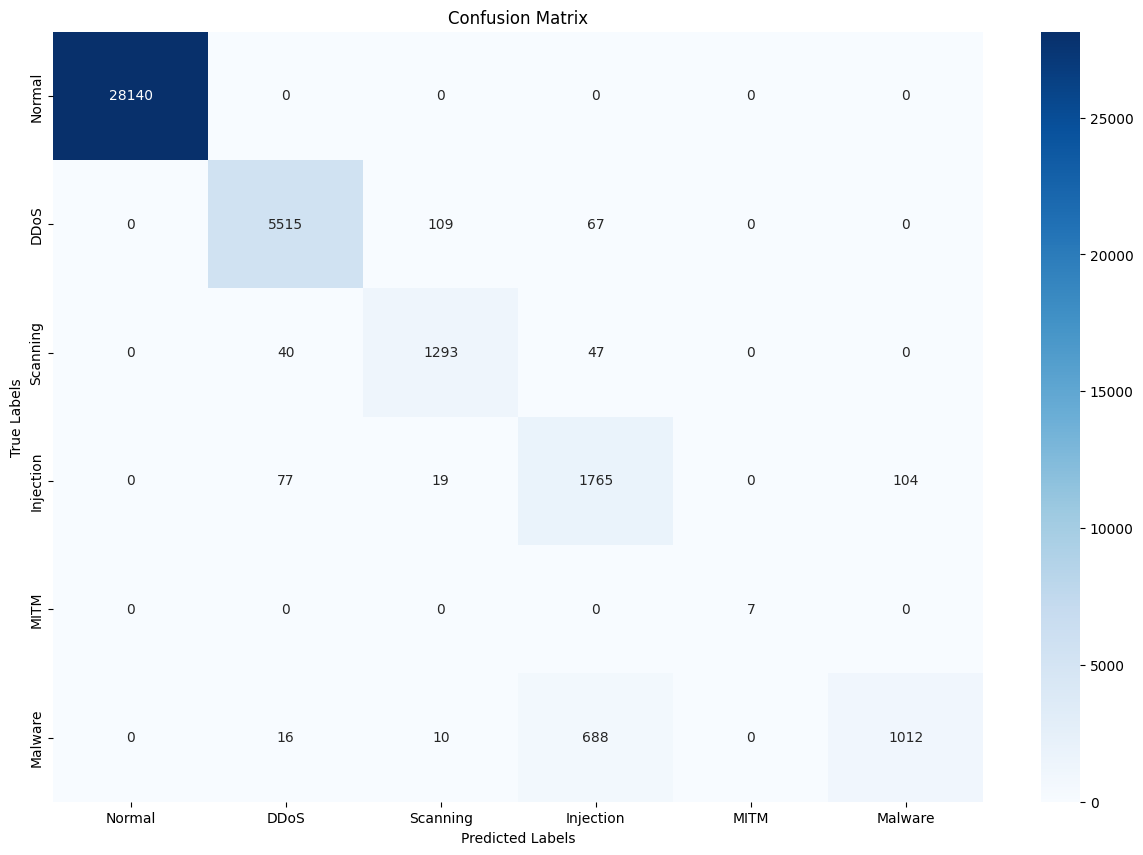

<Figure size 640x480 with 0 Axes>

In [26]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
plt.savefig('confusion_matrix_HPT_6.jpg')

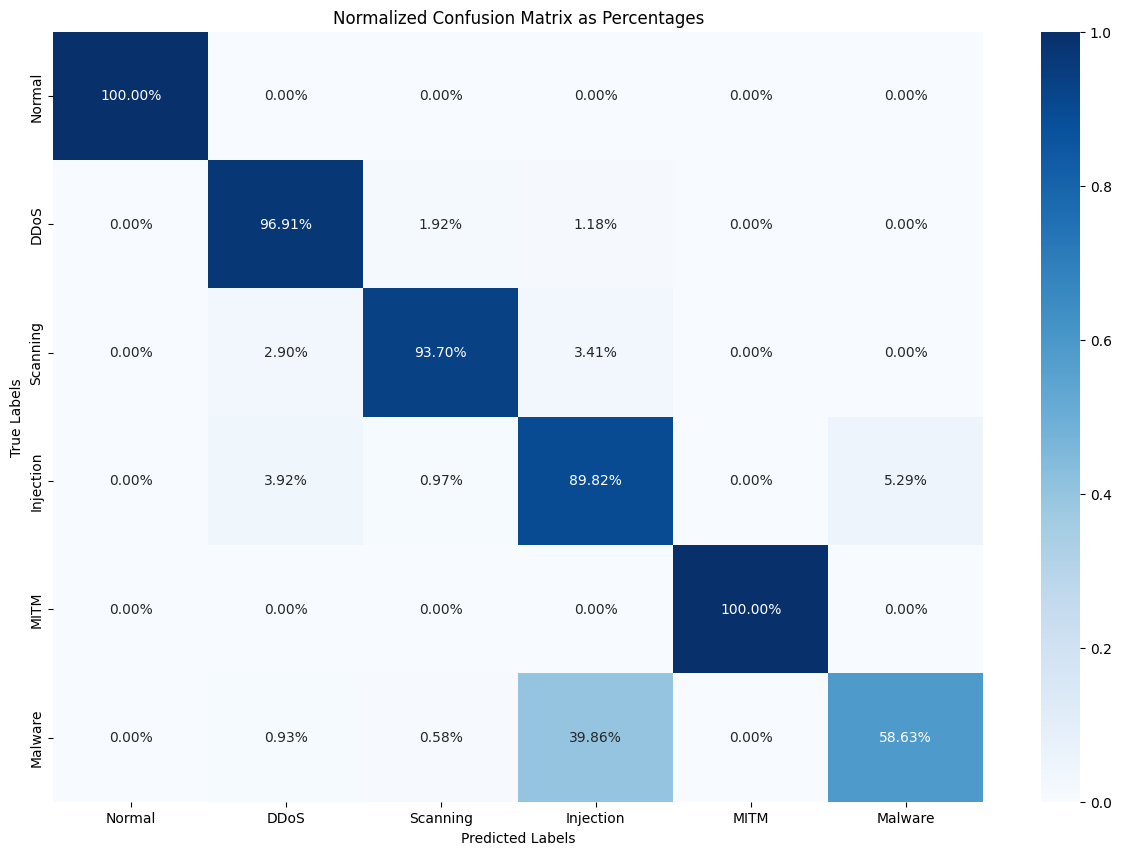

<Figure size 640x480 with 0 Axes>

In [27]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Normalize the confusion matrix by dividing each value by the sum of its row (i.e., the number of true instances for each label)
conf_mat_normalized = conf_mat.astype('float') / conf_mat.sum(axis=1)[:, np.newaxis]

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat_normalized, annot=True, fmt=".2%", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Normalized Confusion Matrix as Percentages')
plt.show()
plt.savefig('confusion_matrix_percent_HPT_6.jpg')

In [28]:
best_model.model.save("results/HPT/hpt_1d_cnn_model_6.h5")

In [29]:
with open('results/HPT/HP_1d_cnn_6.json', 'w') as f:
    json.dump(search_cv.best_params_, f)

[CV] END batch_size=64, dense_units=128, dropout_rate=0.5, epochs=10, filters=128, kernel_size=5, learning_rate=0.0001; total time= 6.9min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.2, epochs=10, filters=64, kernel_size=7, learning_rate=0.001; total time= 4.9min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.2, epochs=10, filters=128, kernel_size=7, learning_rate=0.0001; total time= 6.3min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.3, epochs=10, filters=16, kernel_size=5, learning_rate=0.001; total time= 1.7min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.3, epochs=10, filters=32, kernel_size=3, learning_rate=0.0005; total time= 2.0min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.3, epochs=10, filters=64, kernel_size=3, learning_rate=0.0001; total time= 3.7min
[CV] END batch_size=64, dense_units=128, dropout_rate=0.3, epochs=10, filters=64, kernel_size=7, learning_rate=0.001; total time= 4.8min
[CV] END batch_size=64, dense_units